In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]

import numpy as np
import torch
import arviz as az
import matplotlib.pyplot as plt
import xarray
from ICIW_Plots import figure, make_rect_ax, make_square_ax, cm2inch
from scipy.stats.qmc import LatinHypercube, scale

plt.style.use("ICIWstyle")

In [2]:
from HSA_Cam_B_027_pyro import (
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    kl_divergence_between_models,
)
from HSA_Mo_B_010_pyro import kinetics_model  # homoscedastic

In [3]:
params = {
    "T": (450.0, 600.0),
    "p": (3.0, 9.0),
    "c2h": (0.2, 4.0),
    "c2m": (0.5, 1000.0),
    "c2w": (0.5, 1000.0),
    "c2i": (0.05, 1.0),
}

# Generate the space filling design points

In [4]:
num_samples = 1000
LHsampler = LatinHypercube(d=len(params))
samples = LHsampler.random(n=num_samples)
samples = scale(
    samples, [v[0] for v in params.values()], [v[1] for v in params.values()]
)

samples = xarray.DataArray(
    data=samples,
    dims=["sample", "parameter"],
    coords={"parameter": list(params.keys())},
)
display(samples)

<xarray.DataArray (sample: 1000, parameter: 6)> Size: 48kB
array([[5.92257512e+02, 4.47718563e+00, 3.87803994e+00, 2.83209408e+02,
        1.80628915e+02, 7.80838876e-01],
       [5.11662756e+02, 4.74031093e+00, 3.78601589e-01, 7.42796685e+02,
        3.50501796e+01, 9.34611280e-01],
       [5.91865806e+02, 5.29474790e+00, 9.50648392e-01, 3.63237431e+01,
        4.92851517e+02, 3.49692832e-01],
       ...,
       [5.29527878e+02, 5.02894181e+00, 2.78452524e-01, 6.06753015e+02,
        4.59011213e+02, 8.89373022e-01],
       [4.50498728e+02, 6.93068464e+00, 2.29697415e+00, 7.51549565e+02,
        3.07584509e+01, 7.67683480e-01],
       [4.68616420e+02, 7.17596726e+00, 3.58574683e+00, 4.91407713e+01,
        6.95023575e+02, 4.33912435e-01]], shape=(1000, 6))
Coordinates:
  * parameter  (parameter) <U3 72B 'T' 'p' 'c2h' 'c2m' 'c2w' 'c2i'
Dimensions without coordinates: sample

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\stats\density_utils.py:250: RuntimeWarning: divide by zero encountered in scalar power
  out = t - (2 * N * np.pi**0.5 * f) ** (-0.4)
c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\stats\density_utils.py:246: RuntimeWarning: divide by zero encountered in scalar divide
  t_j = np.power((c1 * (c2 / (N * f))), (2.0 / (3.0 + 2.0 * j)))


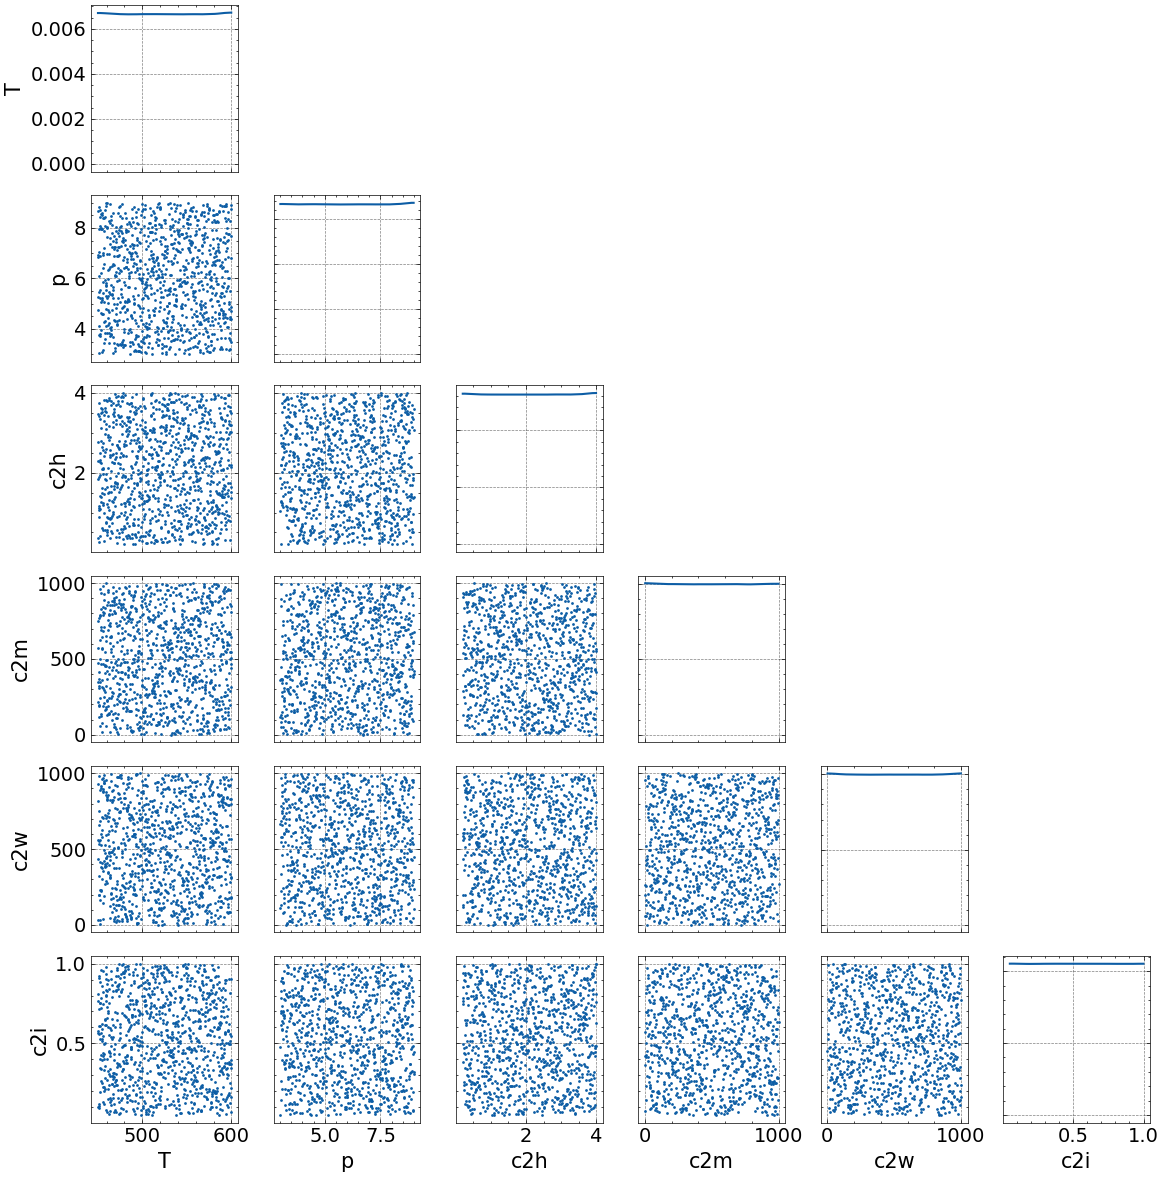

In [5]:
# Convert samples to a format suitable for arviz pair plot
sample_dict = {param: samples.sel(parameter=param).values for param in params.keys()}

az.plot_pair(sample_dict, kind="scatter", marginals=True, figsize=(12, 12))
plt.tight_layout()
plt.show()

Pretty space filling!

## Generate the GT model predictions at these positions

In [6]:
T, p, lat_r = generate_synthetic_data(
    torch.tensor(samples.sel(parameter="T").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="p").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2h").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2m").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2w").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2i").values).reshape(-1, 1),
    noise_std=0.0,
)
T, p, obs_r = generate_synthetic_data(
    torch.tensor(samples.sel(parameter="T").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="p").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2h").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2m").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2w").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2i").values).reshape(-1, 1),
    noise_std=1e-5,
)

array([[<Axes: title={'center': 'lat_r'}>,
        <Axes: title={'center': 'obs_r'}>]], dtype=object)

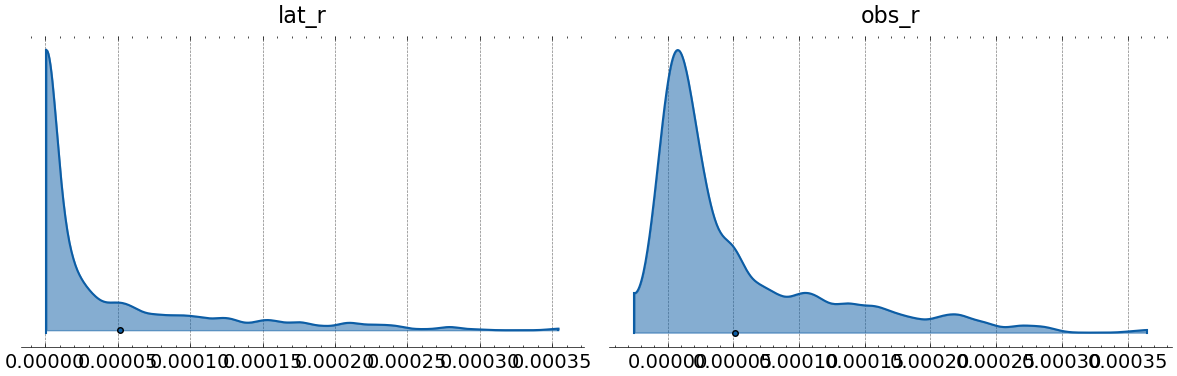

In [7]:
az.plot_density(
    {
        "lat_r": lat_r.numpy().flatten(),
        "obs_r": obs_r.numpy().flatten(),
    },
    figsize=(12, 4),
    hdi_prob=0.999,
    shade=0.5,
)
# ax = plt.gca()
# ax.set_xscale("log")

array([[<Axes: title={'center': 'lat_r'}>]], dtype=object)

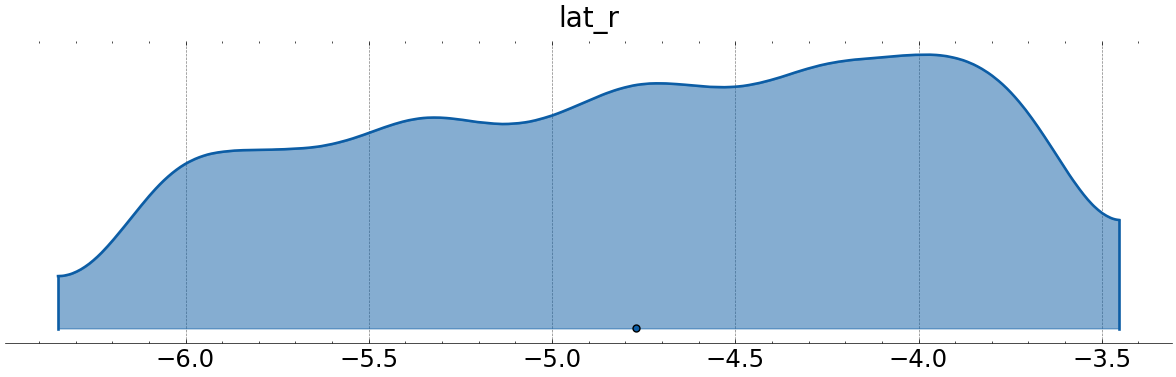

In [8]:
az.plot_density(
    {
        "lat_r": np.log10(lat_r.numpy().flatten()),
    },
    figsize=(12, 4),
    hdi_prob=0.999,
    shade=0.5,
)

In [9]:
data = xarray.Dataset(
    {
        "samples": samples,
        "T": (("sample"), T.numpy().flatten()),
        "p": (("sample", "species"), p.numpy()),
        "latent_r": (("sample"), lat_r.numpy().flatten()),
        "obs_r": (("sample"), obs_r.numpy().flatten()),
    },
    coords={
        "sample": np.arange(num_samples),
        "species": ["CO2", "H2", "H2O", "CH4", "I"],
    },
)
data.attrs["noise"] = "homoscedastic"
data.attrs["sigma"] = 1e-5
display(data)

data.to_netcdf(Path("data/test_HSA_Da_B_001.nc"))

<xarray.Dataset> Size: 120kB
Dimensions:    (parameter: 6, sample: 1000, species: 5)
Coordinates:
  * parameter  (parameter) <U3 72B 'T' 'p' 'c2h' 'c2m' 'c2w' 'c2i'
  * sample     (sample) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * species    (species) <U3 60B 'CO2' 'H2' 'H2O' 'CH4' 'I'
Data variables:
    samples    (sample, parameter) float64 48kB 592.3 4.477 ... 695.0 0.4339
    T          (sample) float64 8kB 592.3 511.7 591.9 ... 529.5 450.5 468.6
    p          (sample, species) float64 40kB 1.757 0.4532 ... 0.0405 4.587
    latent_r   (sample) float64 8kB 0.0001679 1.652e-05 ... 7.472e-07 1.536e-06
    obs_r      (sample) float64 8kB 0.0001751 1.981e-05 ... 2.39e-07 6.485e-06
Attributes:
    noise:    homoscedastic
    sigma:    1e-05